### CA1 – Data Preparation and Exploratory Data Analysis

**Module:** Data Preparation     
**Programme:** Higher Diploma in Data Analytics for Business  
**Student ID:** 2026328  
**Assignment:** CA1  
**Project Topic:** Student Academic Outcome Analysis Using Data Preparation and PCA    
**GitHub Repository:** https://github.com/2026328-Dashzeveg-Purevtogtokh/Data-Preparation-Sep26

### Introduction
This project focuses on preparing and analysing student data. The dataset contains information about students, including their background and academic results. The main aim is to check data quality, clean the data, and explore important patterns. PCA will also be used to reduce the number of features while keeping 99.5% of the variance.

In [1]:
# Import my packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load my dataset
df = pd.read_csv("../data/student_dataV2.csv")
print("Dataset loaded:", df.shape)
display(df.head())

Dataset loaded: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
# Standardise text values
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())

['marital status', 'application mode', 'application order', 'course', 'daytime/evening attendance', 'previous qualification', 'previous qualification (grade)', 'nacionality', "mother's qualification", "father's qualification", "mother's occupation", "father's occupation", 'admission grade', 'displaced', 'educational special needs', 'debtor', 'tuition fees up to date', 'gender', 'scholarship holder', 'age at enrollment', 'international', 'curricular units 1st sem (credited)', 'curricular units 1st sem (enrolled)', 'curricular units 1st sem (evaluations)', 'curricular units 1st sem (approved)', 'curricular units 1st sem (grade)', 'curricular units 1st sem (without evaluations)', 'curricular units 2nd sem (credited)', 'curricular units 2nd sem (enrolled)', 'curricular units 2nd sem (evaluations)', 'curricular units 2nd sem (approved)', 'curricular units 2nd sem (grade)', 'curricular units 2nd sem (without evaluations)', 'unemployment rate', 'inflation rate', 'gdp', 'target']


In [3]:
# Standardise column names
df.columns = [
    col.strip().lower().replace(" ", "_").replace("'", "_") for col in df.columns
]

In [4]:
df = df.map(lambda s: s.lower() if isinstance(s, str) else s)

In [5]:
df.head()

,marital_status,application_mode,application_order,course,daytime/evening_attendance,previous_qualification,previous_qualification_(grade),nacionality,mother_s_qualification,father_s_qualification,...,curricular_units_2nd_sem_(credited),curricular_units_2nd_sem_(enrolled),curricular_units_2nd_sem_(evaluations),curricular_units_2nd_sem_(approved),curricular_units_2nd_sem_(grade),curricular_units_2nd_sem_(without_evaluations),unemployment_rate,inflation_rate,gdp,target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,graduate


### 1. Dataset characterisation

In [6]:
# Dataset size
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 4424
Columns: 37


In [7]:
# Data quality checks
print("Missing (NaN):", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing (NaN): 21
Duplicate rows: 0


In [8]:
# Data types
print("\nData types:")
print(df.dtypes)


Data types:
marital_status                                        str
application_mode                                  float64
application_order                                 float64
course                                            float64
daytime/evening_attendance                          int64
previous_qualification                              int64
previous_qualification_(grade)                    float64
nacionality                                           str
mother_s_qualification                              int64
father_s_qualification                            float64
mother_s_occupation                               float64
father_s_occupation                                   str
admission_grade                                   float64
displaced                                             str
educational_special_needs                           int64
debtor                                            float64
tuition_fees_up_to_date                               str
g

In [9]:
# Target categories
print("\nTarget distribution:")
print(df["target"].value_counts(dropna=False))


Target distribution:
target
graduate    2208
dropout     1420
enrolled     794
grad           1
drop           1
Name: count, dtype: int64


In [10]:
# Target percentages
print("\nTarget percentages:")
print(df["target"].value_counts(normalize=True) * 100)


Target percentages:
target
graduate    49.909584
dropout     32.097649
enrolled    17.947559
grad         0.022604
drop         0.022604
Name: proportion, dtype: float64


**Interpretation:** The dataset contains **4,424 student records and 37 columns**. There are 36 input features and one target variable. The dataset has 21 missing values (NaN) and no duplicate rows.
One important issue is the missing values. Missing data can affect the quality of the analysis and may cause problems when applying PCA. Therefore, missing values need to be checked and handled before further analysis.

### 2. Read the data dictionary and choose data types
Some columns contain measurements, for example age and admission grade. Other columns use numbers as category labels, for example gender and course. We should not treat category labels as measurements.

In [11]:
# Import my dataset
dictionary = pd.read_excel("../data/student_data_dictionary.xlsx")
dictionary.head()

,Variable Name,Role,Type,Demographic,Description,Units
0,Marital Status,Feature,Integer,Marital Status,1 – single 2 – married 3 – widower 4 – divorce...,NaN
1,Application mode,Feature,Integer,NaN,1 - 1st phase - general contingent 2 - Ordinan...,NaN
2,Application order,Feature,Integer,NaN,Application order (between 0 - first choice; a...,NaN
3,Course,Feature,Integer,NaN,33 - Biofuel Production Technologies 171 - Ani...,NaN
4,Daytime/evening attendance,Feature,Integer,NaN,1 – daytime 0 - evening,NaN


In [12]:
dictionary.columns = dictionary.columns.str.strip().str.lower()
print(dictionary.columns.tolist())

['variable name', 'role', 'type', 'demographic', 'description', 'units']


In [13]:
# Rename target value
dictionary.columns = [
    col.strip().lower().replace(" ", "_") for col in dictionary.columns
]

In [14]:
dictionary = dictionary.map(lambda s: s.lower() if isinstance(s, str) else s)

In [15]:
# Check the dictionary
print("Dictionary shape:", dictionary.shape)
print("Dictionary columns:", dictionary.columns.tolist())

Dictionary shape: (37, 6)
Dictionary columns: ['variable_name', 'role', 'type', 'demographic', 'description', 'units']


In [16]:
category_cols = df.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

numeric_cols = df.select_dtypes(include="number").columns.tolist()

print("Categorical columns:", category_cols)
print("Numerical columns:", numeric_cols)

Categorical columns: ['marital_status', 'nacionality', 'father_s_occupation', 'displaced', 'tuition_fees_up_to_date', 'age_at_enrollment', 'curricular_units_1st_sem_(credited)', 'target']
Numerical columns: ['application_mode', 'application_order', 'course', 'daytime/evening_attendance', 'previous_qualification', 'previous_qualification_(grade)', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'admission_grade', 'educational_special_needs', 'debtor', 'gender', 'scholarship_holder', 'international', 'curricular_units_1st_sem_(enrolled)', 'curricular_units_1st_sem_(evaluations)', 'curricular_units_1st_sem_(approved)', 'curricular_units_1st_sem_(grade)', 'curricular_units_1st_sem_(without_evaluations)', 'curricular_units_2nd_sem_(credited)', 'curricular_units_2nd_sem_(enrolled)', 'curricular_units_2nd_sem_(evaluations)', 'curricular_units_2nd_sem_(approved)', 'curricular_units_2nd_sem_(grade)', 'curricular_units_2nd_sem_(without_evaluations)', 'unemployment_rate

In [17]:
dictionary

,variable_name,role,type,demographic,description,units
0,marital status,feature,integer,marital status,1 – single 2 – married 3 – widower 4 – divorce...,NaN
1,application mode,feature,integer,NaN,1 - 1st phase - general contingent 2 - ordinan...,NaN
2,application order,feature,integer,NaN,application order (between 0 - first choice; a...,NaN
3,course,feature,integer,NaN,33 - biofuel production technologies 171 - ani...,NaN
4,daytime/evening attendance,feature,integer,NaN,1 – daytime 0 - evening,NaN
5,previous qualification,feature,integer,education level,1 - secondary education 2 - higher education -...,NaN
6,previous qualification (grade),feature,continuous,NaN,grade of previous qualification (between 0 and...,NaN
7,nacionality,feature,integer,nationality,1 - portuguese; 2 - german; 6 - spanish; 11 - ...,NaN
8,mother's qualification,feature,integer,education level,1 - secondary education - 12th year of schooli...,NaN
9,father's qualification,feature,integer,education level,1 - secondary education - 12th year of schooli...,NaN


In [18]:
# Clean column names my data frame
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("/", "_", regex=False)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("'", "_", regex=False)
)

# Fix spelling
df = df.rename(columns={"nacionality": "nationality"})
print(df.columns.tolist())


['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'nationality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'admission_grade', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'target']


In [19]:
# Clean variable names for dictionary file
dictionary["variable_name"] = (
    dictionary["variable_name"]
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("/", "_", regex=False)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("'", "_", regex=False)
)

# Fix spelling in the values
dictionary["variable_name"] = dictionary["variable_name"].replace(
    {"nacionality": "nationality"}
)

print(dictionary["variable_name"].tolist())

['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'nationality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'admission_grade', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'target']


In [20]:
dictionary.head()

,variable_name,role,type,demographic,description,units
0,marital_status,feature,integer,marital status,1 – single 2 – married 3 – widower 4 – divorce...,NaN
1,application_mode,feature,integer,NaN,1 - 1st phase - general contingent 2 - ordinan...,NaN
2,application_order,feature,integer,NaN,application order (between 0 - first choice; a...,NaN
3,course,feature,integer,NaN,33 - biofuel production technologies 171 - ani...,NaN
4,daytime_evening_attendance,feature,integer,NaN,1 – daytime 0 - evening,NaN


In [21]:
print(dictionary["type"].unique())

<StringArray>
['integer', 'continuous', 'categorical']
Length: 3, dtype: str


In [22]:
df.columns

Index(['marital_status', 'application_mode', 'application_order', 'course',
       'daytime_evening_attendance', 'previous_qualification',
       'previous_qualification_grade', 'nationality', 'mother_s_qualification',
       'father_s_qualification', 'mother_s_occupation', 'father_s_occupation',
       'admission_grade', 'displaced', 'educational_special_needs', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'age_at_enrollment', 'international',
       'curricular_units_1st_sem_credited',
       'curricular_units_1st_sem_enrolled',
       'curricular_units_1st_sem_evaluations',
       'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade',
       'curricular_units_1st_sem_without_evaluations',
       'curricular_units_2nd_sem_credited',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_evaluations',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'curricular_units_2nd_sem

In [23]:
for col in df.columns:
    if col == "target":
        continue

    values = df[col]
    converted = pd.to_numeric(values, errors="coerce")
    invalid = values.notna() & converted.isna()

    if invalid.any():
        print(f"\n--- {col} ---")
        print(values[invalid].value_counts(dropna=False))


--- marital_status ---
marital_status
?    1
Name: count, dtype: int64

--- nationality ---
nationality
?    1
Name: count, dtype: int64

--- father_s_occupation ---
father_s_occupation
five    1
Name: count, dtype: int64

--- displaced ---
displaced
?    1
Name: count, dtype: int64

--- tuition_fees_up_to_date ---
tuition_fees_up_to_date
?    1
Name: count, dtype: int64

--- age_at_enrollment ---
age_at_enrollment
unknown    1
Name: count, dtype: int64

--- curricular_units_1st_sem_credited ---
curricular_units_1st_sem_credited
na    1
Name: count, dtype: int64


In [24]:
# Replace missing-value markers, including variations in case and spaces
df = df.replace(r"(?i)^\s*(?:\?|unknown|na)\s*$", pd.NA, regex=True)

# Run this only after confirming that "five" means occupation code 5
df["father_s_occupation"] = df["father_s_occupation"].replace(
    r"(?i)^\s*five\s*$", 5, regex=True
)

In [25]:
# dictionary = dictionary.replace(r"(?i)^\s*(?:\?|unknown|na)\s*$", pd.NA, regex=True)

In [26]:
# Convert columns using dictionary types
for _, row in dictionary.iterrows():
    col = row["variable_name"]
    data_type = row["type"]

    if col not in df.columns:
        print("Column not found:", col)
        continue

    if col == "target":
        df[col] = df[col].astype("category")

    elif col in ["curricular_units_1st_sem_grade", "curricular_units_2nd_sem_grade"]:
        # These are average grades
        df[col] = pd.to_numeric(df[col], errors="raise").astype("Float64")

    elif data_type == "continuous":
        df[col] = pd.to_numeric(df[col], errors="raise").astype("Float64")

    elif data_type == "integer":
        df[col] = pd.to_numeric(df[col], errors="raise").astype("Int64")

# Check data types
print(df.dtypes)


marital_status                                     Int64
application_mode                                   Int64
application_order                                  Int64
course                                             Int64
daytime_evening_attendance                         Int64
previous_qualification                             Int64
previous_qualification_grade                     Float64
nationality                                        Int64
mother_s_qualification                             Int64
father_s_qualification                             Int64
mother_s_occupation                                Int64
father_s_occupation                                Int64
admission_grade                                  Float64
displaced                                          Int64
educational_special_needs                          Int64
debtor                                             Int64
tuition_fees_up_to_date                            Int64
gender                         

**Interpretation:** I checked the data dictionary to understand the correct data types. The dataset contains integer, continuous, and categorical features.
I converted integer features to integer data types and continuous features to floating-point numbers. I also kept the semester grade columns as floating-point numbers because they contain average grades.
The target column was converted to a categorical data type because it represents three student outcomes.
This step is important because correct data types help improve data quality and prepare the dataset for further analysis.

In [27]:
category_cols = df.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

numeric_cols = df.select_dtypes(include="number").columns.tolist()

print("Categorical columns:", category_cols)
print("Numerical columns:", numeric_cols)

Categorical columns: ['target']
Numerical columns: ['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'nationality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'admission_grade', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp'

In [28]:
df

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mother_s_qualification,father_s_qualification,...,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.0,0,10.8,1.4,1.74,dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.0,0,10.8,1.4,1.74,dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.4,0,9.4,-0.8,-3.12,graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.0,0,13.9,-0.3,0.79,graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,9773,1,1,125.0,1,1,1,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,graduate
4420,1,1,2,9773,1,1,120.0,105,1,1,...,0,6,6,2,11.0,0,11.1,0.6,2.02,dropout
4421,1,1,1,9500,1,1,154.0,1,37,37,...,0,8,9,1,13.5,0,13.9,-0.3,0.79,dropout
4422,1,1,1,9147,1,1,180.0,1,37,37,...,0,5,6,5,12.0,0,9.4,-0.8,-3.12,graduate


In [29]:
data_type = df.copy()

In [30]:
import re

pattern = re.compile(r"(?<!\S)(\d+)\s*[-–—]\s*")


def extract_mapping(description):
    text = str(description)
    matches = list(pattern.finditer(text))
    mapping = {}

    for i, match in enumerate(matches):
        code = int(match.group(1))
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        label = text[match.end() : end].strip(" ;\n\r\t")
        mapping[code] = label

    return mapping


descriptions = dictionary.set_index("variable_name")["description"]

# Select columns currently stored as numbers
numeric_columns = data_type.select_dtypes(include="number").columns.tolist()

for col in numeric_columns:
    if col not in descriptions.index:
        print(f"No dictionary entry: {col}")
        continue

    description = descriptions.loc[col]

    # Only process descriptions that start with a code-to-label mapping
    if pd.isna(description) or not re.match(r"^\s*\d+\s*[-–—]\s*", str(description)):
        continue

    mapping = extract_mapping(description)
    codes = data_type[col]

    unmatched = codes.notna() & ~codes.isin(mapping)
    if unmatched.any():
        print(f"Unmapped codes in {col}:", codes[unmatched].unique().tolist())

    labels = codes.map(mapping).astype("category")
    label_col = f"{col}_label"

    if label_col in data_type.columns:
        data_type = data_type.drop(columns=label_col)

    data_type.insert(data_type.columns.get_loc(col) + 1, label_col, labels)

with pd.option_context("display.max_columns", None):
    display(data_type.head())

,marital_status,marital_status_label,application_mode,application_mode_label,application_order,course,course_label,daytime_evening_attendance,daytime_evening_attendance_label,previous_qualification,previous_qualification_label,previous_qualification_grade,nationality,nationality_label,mother_s_qualification,mother_s_qualification_label,father_s_qualification,father_s_qualification_label,mother_s_occupation,mother_s_occupation_label,father_s_occupation,father_s_occupation_label,admission_grade,displaced,displaced_label,educational_special_needs,educational_special_needs_label,debtor,debtor_label,tuition_fees_up_to_date,tuition_fees_up_to_date_label,gender,gender_label,scholarship_holder,scholarship_holder_label,age_at_enrollment,international,international_label,curricular_units_1st_sem_credited,curricular_units_1st_sem_enrolled,curricular_units_1st_sem_evaluations,curricular_units_1st_sem_approved,curricular_units_1st_sem_grade,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,single,17,2nd phase - general contingent,5,171,animation and multimedia design,1,daytime,1,secondary education,122.0,1,portuguese,19,basic education 3rd cycle (9th/10th/11th year)...,12,other - 11th year of schooling,5,"personal services, security and safety workers...",9,unskilled workers,127.3,1,yes,0,no,0,no,1,yes,1,male,0,no,20,0,no,0,0,0,0,0.0,0,0,0,0,0,0.0,0,10.8,1.4,1.74,dropout
1,1,single,15,international student (bachelor),1,9254,tourism,1,daytime,1,secondary education,160.0,1,portuguese,1,secondary education - 12th year of schooling o...,3,higher education - degree,3,intermediate level technicians and professions,3,intermediate level technicians and professions,142.5,1,yes,0,no,0,no,0,no,1,male,0,no,19,0,no,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduate
2,1,single,1,1st phase - general contingent,5,9070,communication design,1,daytime,1,secondary education,122.0,1,portuguese,37,basic education 1st cycle (4th/5th year) or eq...,37,basic education 1st cycle (4th/5th year) or eq...,9,unskilled workers,9,unskilled workers,124.8,1,yes,0,no,0,no,0,no,1,male,0,no,19,0,no,0,6,0,0,0.0,0,0,6,0,0,0.0,0,10.8,1.4,1.74,dropout
3,1,single,17,2nd phase - general contingent,2,9773,journalism and communication,1,daytime,1,secondary education,122.0,1,portuguese,38,basic education 2nd cycle (6th/7th/8th year) o...,37,basic education 1st cycle (4th/5th year) or eq...,5,"personal services, security and safety workers...",3,intermediate level technicians and professions,119.6,1,yes,0,no,0,no,1,yes,0,female,0,no,20,0,no,0,6,8,6,13.428571,0,0,6,10,5,12.4,0,9.4,-0.8,-3.12,graduate
4,2,married,39,over 23 years old,1,8014,social service (evening attendance),0,evening,1,secondary education,100.0,1,portuguese,37,basic education 1st cycle (4th/5th year) or eq...,38,basic education 2nd cycle (6th/7th/8th year) o...,9,unskilled workers,9,unskilled workers,141.5,0,no,0,no,0,no,1,yes,0,female,0,no,45,0,no,0,6,9,5,12.333333,0,0,6,6,6,13.0,0,13.9,-0.3,0.79,graduate


In [31]:
print("Label columns:", data_type.columns.str.endswith("_label").sum())

Label columns: 17


In [32]:
label_cols = [col for col in data_type.columns if col.endswith("_label")]
display(data_type[label_cols].head())

,marital_status_label,application_mode_label,course_label,daytime_evening_attendance_label,previous_qualification_label,nationality_label,mother_s_qualification_label,father_s_qualification_label,mother_s_occupation_label,father_s_occupation_label,displaced_label,educational_special_needs_label,debtor_label,tuition_fees_up_to_date_label,gender_label,scholarship_holder_label,international_label
0,single,2nd phase - general contingent,animation and multimedia design,daytime,secondary education,portuguese,basic education 3rd cycle (9th/10th/11th year)...,other - 11th year of schooling,"personal services, security and safety workers...",unskilled workers,yes,no,no,yes,male,no,no
1,single,international student (bachelor),tourism,daytime,secondary education,portuguese,secondary education - 12th year of schooling o...,higher education - degree,intermediate level technicians and professions,intermediate level technicians and professions,yes,no,no,no,male,no,no
2,single,1st phase - general contingent,communication design,daytime,secondary education,portuguese,basic education 1st cycle (4th/5th year) or eq...,basic education 1st cycle (4th/5th year) or eq...,unskilled workers,unskilled workers,yes,no,no,no,male,no,no
3,single,2nd phase - general contingent,journalism and communication,daytime,secondary education,portuguese,basic education 2nd cycle (6th/7th/8th year) o...,basic education 1st cycle (4th/5th year) or eq...,"personal services, security and safety workers...",intermediate level technicians and professions,yes,no,no,yes,female,no,no
4,married,over 23 years old,social service (evening attendance),evening,secondary education,portuguese,basic education 1st cycle (4th/5th year) or eq...,basic education 2nd cycle (6th/7th/8th year) o...,unskilled workers,unskilled workers,no,no,no,yes,female,no,no


In [33]:
# data_cleaning.to_excel("../data/student_data_labelled.xlsx", index=False)

In [34]:
label_cols = [col for col in data_type.columns if col.endswith("_label")]
label_cols

['marital_status_label',
 'application_mode_label',
 'course_label',
 'daytime_evening_attendance_label',
 'previous_qualification_label',
 'nationality_label',
 'mother_s_qualification_label',
 'father_s_qualification_label',
 'mother_s_occupation_label',
 'father_s_occupation_label',
 'displaced_label',
 'educational_special_needs_label',
 'debtor_label',
 'tuition_fees_up_to_date_label',
 'gender_label',
 'scholarship_holder_label',
 'international_label']

**Interpretation:** I cleaned the column names by changing them to lowercase and using underscores instead of spaces and special characters. I also checked the data types using the data dictionary. The dataset has `19 numeric features` and `17 categorical + target` features.Some categorical features were stored as numbers, such as course, gender, and application mode. I classified them as categorical because these numbers represent different groups.This step helps make the dataset more consistent and prepares the features for further analysis.

#### Cleaning: Find Special Missing Values and Inconsistent Labels.

In [56]:
# Make a copy of the original dataset
data_cleaning = df.copy()

In [57]:
# Categorical features
category_cols = [
    "marital_status",
    "application_mode",
    "course",
    "daytime_evening_attendance",
    "previous_qualification",
    "nationality",
    "mother_s_qualification",
    "father_s_qualification",
    "mother_s_occupation",
    "father_s_occupation",
    "displaced",
    "educational_special_needs",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder",
    "international",
]

# Numeric features
numeric_cols = [
    "application_order",
    "previous_qualification_grade",
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations",
    "curricular_units_2nd_sem_credited",
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_evaluations",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",
    "curricular_units_2nd_sem_without_evaluations",
    "unemployment_rate",
    "inflation_rate",
    "gdp",
]

In [58]:
data_cleaning[category_cols] = data_cleaning[category_cols].astype("category")
# Check the updated types
print(data_cleaning[category_cols].dtypes)

marital_status                category
application_mode              category
course                        category
daytime_evening_attendance    category
previous_qualification        category
nationality                   category
mother_s_qualification        category
father_s_qualification        category
mother_s_occupation           category
father_s_occupation           category
displaced                     category
educational_special_needs     category
debtor                        category
tuition_fees_up_to_date       category
gender                        category
scholarship_holder            category
international                 category
dtype: object


In [59]:
category_cols = data_cleaning.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

numeric_cols = data_cleaning.select_dtypes(include="number").columns.tolist()

print(f"Categorical columns ({len(category_cols)}):", category_cols)
print(f"Numerical columns ({len(numeric_cols)}):", numeric_cols)
print("Total columns:", data_cleaning.shape[1])

Categorical columns (18): ['marital_status', 'application_mode', 'course', 'daytime_evening_attendance', 'previous_qualification', 'nationality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international', 'target']
Numerical columns (19): ['application_order', 'previous_qualification_grade', 'admission_grade', 'age_at_enrollment', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_ra

In [60]:
data_cleaning.isna().sum()

marital_status                                  1
application_mode                                1
application_order                               1
course                                          3
daytime_evening_attendance                      0
previous_qualification                          0
previous_qualification_grade                    4
nationality                                     1
mother_s_qualification                          0
father_s_qualification                          1
mother_s_occupation                             1
father_s_occupation                             1
admission_grade                                 2
displaced                                       1
educational_special_needs                       0
debtor                                          1
tuition_fees_up_to_date                         2
gender                                          0
scholarship_holder                              0
age_at_enrollment                               2


In [61]:
# Find question marks
print("Question marks:", (data_cleaning == "?").sum().sum())

Question marks: 0


In [62]:
# Replace question marks with NaN
data_cleaning = data_cleaning.replace(r"^\s*\?\s*$", np.nan, regex=True)

In [63]:
# Check missing values after cleaning
print("Missing values after:", data_cleaning.isna().sum().sum())

Missing values after: 27


In [64]:
data_cleaning.isna().sum()

marital_status                                  1
application_mode                                1
application_order                               1
course                                          3
daytime_evening_attendance                      0
previous_qualification                          0
previous_qualification_grade                    4
nationality                                     1
mother_s_qualification                          0
father_s_qualification                          1
mother_s_occupation                             1
father_s_occupation                             1
admission_grade                                 2
displaced                                       1
educational_special_needs                       0
debtor                                          1
tuition_fees_up_to_date                         2
gender                                          0
scholarship_holder                              0
age_at_enrollment                               2


In [65]:
# Check target values before cleaning
print("Target before cleaning:")
print(data_cleaning["target"].value_counts(drona=False))


Target before cleaning:


TypeError: IndexOpsMixin.value_counts() got an unexpected keyword argument 'drona'. Did you mean 'dropna'?

In [66]:
for col in data_cleaning.columns:
    print(f"\n--- {col} ---")
    print(data_cleaning[col].value_counts(dropna=False))


--- marital_status ---
marital_status
1      3918
2       379
4        91
5        25
6         6
3         4
NaN       1
Name: count, dtype: int64

--- application_mode ---
application_mode
1      1708
17      872
39      785
43      312
44      212
7       139
18      124
42       77
51       59
16       38
53       35
15       30
5        16
10       10
2         3
26        1
27        1
57        1
NaN       1
Name: count, dtype: int64

--- application_order ---
application_order
1       3026
2        547
3        308
4        249
5        154
6        137
9          1
0          1
<NA>       1
Name: count, dtype: Int64

--- course ---
course
9500    766
9147    379
9238    355
9085    337
9773    331
9991    268
9670    267
9254    252
9070    226
171     215
8014    215
9003    210
9853    192
9119    170
9130    140
9556     86
33       12
NaN       3
Name: count, dtype: int64

--- daytime_evening_attendance ---
daytime_evening_attendance
1    3941
0     483
Name: count, dtype

In [69]:
# Standardise target labels
data_cleaning["target"] = data_cleaning["target"].replace(
    {"grad": "graduate", "drop": "dropout"}
)
# Check target values after cleaning
print("\nTarget after cleaning:")
print(data_cleaning["target"].value_counts(dropna=False))


Target after cleaning:
target
graduate    2209
dropout     1421
enrolled     794
drop           0
grad           0
Name: count, dtype: int64


In [70]:
data_cleaning.isnull().sum()

marital_status                                  1
application_mode                                1
application_order                               1
course                                          3
daytime_evening_attendance                      0
previous_qualification                          0
previous_qualification_grade                    4
nationality                                     1
mother_s_qualification                          0
father_s_qualification                          1
mother_s_occupation                             1
father_s_occupation                             1
admission_grade                                 2
displaced                                       1
educational_special_needs                       0
debtor                                          1
tuition_fees_up_to_date                         2
gender                                          0
scholarship_holder                              0
age_at_enrollment                               2


In [71]:
# Check missing values
missing = data_cleaning.isnull().sum()
# Show only columns with missing values
print(missing[missing > 0])

marital_status                       1
application_mode                     1
application_order                    1
course                               3
previous_qualification_grade         4
nationality                          1
father_s_qualification               1
mother_s_occupation                  1
father_s_occupation                  1
admission_grade                      2
displaced                            1
debtor                               1
tuition_fees_up_to_date              2
age_at_enrollment                    2
international                        1
curricular_units_1st_sem_credited    1
curricular_units_1st_sem_grade       1
curricular_units_2nd_sem_enrolled    1
curricular_units_2nd_sem_grade       1
dtype: int64


In [72]:
# Fill numeric missing values with median
for col in numeric_cols:
    data_cleaning[col] = pd.to_numeric(data_cleaning[col], errors="coerce")
    data_cleaning[col] = data_cleaning[col].fillna(data_cleaning[col].median())

# Fill categorical missing values with mode
for col in category_cols:
    if data_cleaning[col].isna().any():
        data_cleaning[col] = data_cleaning[col].fillna(
            data_cleaning[col].mode().iloc[0]
        )

In [73]:
# Check missing values after cleaning
print("Missing after:", data_cleaning.isna().sum().sum())

Missing after: 0


In [74]:
# Count duplicate rows
print("Duplicate rows:", data_cleaning.duplicated().sum())

Duplicate rows: 0


In [75]:
# Standardise target labels
data_cleaning["target"] = (
    data_cleaning["target"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({"grad": "graduate", "drop": "dropout"})
    .astype("category")
)

# Check target values after cleaning
print("\nTarget after cleaning:")
print(data_cleaning["target"].value_counts(dropna=False))


Target after cleaning:
target
graduate    2209
dropout     1421
enrolled     794
Name: count, dtype: int64


In [76]:
# data_cleaning.to_excel("../data/student_data_cleaned.xlsx", index=False)

**Interpretation:** I checked the dataset for missing values and inconsistent target labels. Some missing values were represented by the question mark symbol (?). I changed these values to NaN so they can be handled correctly during data preparation.
I also found inconsistent labels in the target column, such as "grad" and "drop". I changed them to "graduate" and "dropout". This makes the target categories more consistent.
These changes are important because missing values and incorrect labels can affect the quality of the analysis.
`For numerical features`, I chose median imputation because the median is less affected by extreme values. 
`For categorical features`, mode imputation is suitable because it uses the most common category.

#### Exploratory Data Analysis (EDA) 
Exploratory Data Analysis (EDA) is used to understand the dataset and identify important patterns.
In this section, I will use different charts to explore student information, including academic outcomes, age, admission grades, and academic performance.
These visualisations can help identify differences between student groups and possible outliers before applying PCA.

In [77]:
label_cols = [col for col in data_type.columns if col.endswith("_label")]

data_eda = data_cleaning.copy()

# Pandas matches rows using their index
data_eda[label_cols] = data_type[label_cols]

display(data_eda.head())

,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mother_s_qualification,father_s_qualification,...,father_s_qualification_label,mother_s_occupation_label,father_s_occupation_label,displaced_label,educational_special_needs_label,debtor_label,tuition_fees_up_to_date_label,gender_label,scholarship_holder_label,international_label
0,1,17,5,171,1,1,122.0,1,19,12,...,other - 11th year of schooling,"personal services, security and safety workers...",unskilled workers,yes,no,no,yes,male,no,no
1,1,15,1,9254,1,1,160.0,1,1,3,...,higher education - degree,intermediate level technicians and professions,intermediate level technicians and professions,yes,no,no,no,male,no,no
2,1,1,5,9070,1,1,122.0,1,37,37,...,basic education 1st cycle (4th/5th year) or eq...,unskilled workers,unskilled workers,yes,no,no,no,male,no,no
3,1,17,2,9773,1,1,122.0,1,38,37,...,basic education 1st cycle (4th/5th year) or eq...,"personal services, security and safety workers...",intermediate level technicians and professions,yes,no,no,yes,female,no,no
4,2,39,1,8014,0,1,100.0,1,37,38,...,basic education 2nd cycle (6th/7th/8th year) o...,unskilled workers,unskilled workers,no,no,no,yes,female,no,no


In [78]:
data_eda["target"].value_counts()

target
graduate    2209
dropout     1421
enrolled     794
Name: count, dtype: int64

target
graduate    2209
dropout     1421
enrolled     794
Name: count, dtype: int64


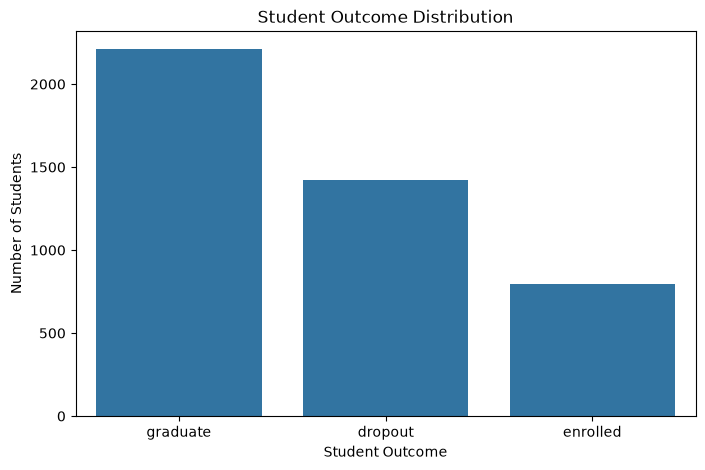

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check the target distribution
target_counts = data_eda["target"].value_counts()

print(target_counts)

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.countplot(data=data_eda, x="target", order=["graduate", "dropout", "enrolled"])

plt.title("Student Outcome Distribution")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")

plt.show()


**Interpretation:** The bar chart shows the number of students in three categories: 
`graduate`, `dropout`, and `enrolled`. The graduate group has the largest number of students, with 2,209 records. The dropout group contains 1,421 students, while the enrolled group has 794 students. The results show that the target categories are not equally balanced. This may affect machine learning models because the model may learn more from the larger groups.

In [83]:
# Check age statistics
print(data_eda["age_at_enrollment"].describe())

count       4424.0
mean     23.265371
std       7.587644
min           17.0
25%           19.0
50%           20.0
75%           25.0
max           70.0
Name: age_at_enrollment, dtype: Float64


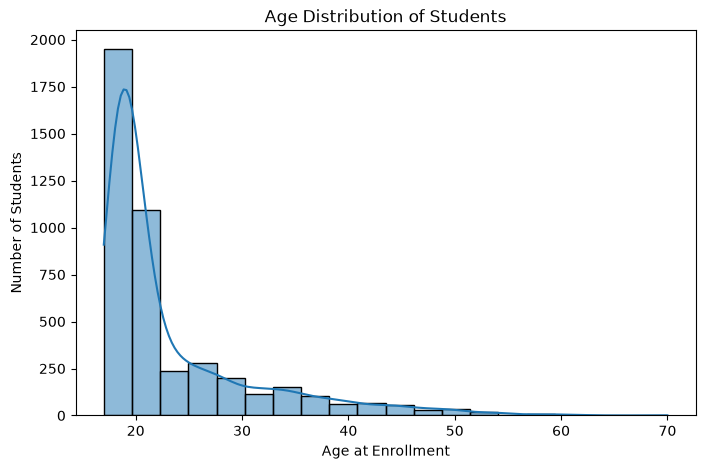

In [ ]:
# Practice chart: Age distribution, if the column is numeric.
plt.figure(figsize=(8, 5))

sns.histplot(data=data_eda, x="age_at_enrollment", bins=20, kde=True)

plt.title("Age Distribution of Students")
plt.xlabel("Age at Enrollment")
plt.ylabel("Number of Students")

plt.show()